# Bayesian Analysis of Rastrigin Function using PyMC

This notebook demonstrates Bayesian parameter estimation for the Rastrigin function using PyMC with MCMC sampling. We'll perform iterative Bayesian inference by using posterior distributions from previous runs as priors for new data.

## Overview
- **Function**: Rastrigin function with multiple parameters (A0, A1, A2, omega1, omega2, chi1, chi2)
- **Method**: PyMC with NUTS sampler
- **Goal**: Estimate parameters from noisy observations and update beliefs iteratively

## 1. Import Required Libraries

In [1]:
import typing as t

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import pytensor as pt
from scipy import stats

# Configure matplotlib for better plots
plt.style.use('default')
%matplotlib inline

print("Libraries imported successfully!")
print(f"PyMC version: {pm.__version__}")
print(f"ArviZ version: {az.__version__}")

Libraries imported successfully!
PyMC version: 5.25.1
ArviZ version: 0.22.0


## 2. Import Functions from Current File

In [2]:
# Import functions from our main Python file
from HSA_Cam_A_002 import gen_data, pt_rastrigin, _from_posterior, build_model

# Import Rastrigin function and parameters
from data.rastrigin import rastrigin, noisy_rastrigin, params

print("Functions imported successfully!")
print(f"True Rastrigin parameters: {params}")

Functions imported successfully!
True Rastrigin parameters: [50, 10, 10, 2.5132741228718345, 3.7699111843077517, 1, 2]


## 4. Execute Main Functionality

### 4.1 First Bayesian Inference Run

Generating first dataset...
Data generated:
  X shape: (20, 2)
  Y shape: (20,)
  Y range: [52.53, 253.65]
  Y mean: 120.66 ± 51.91


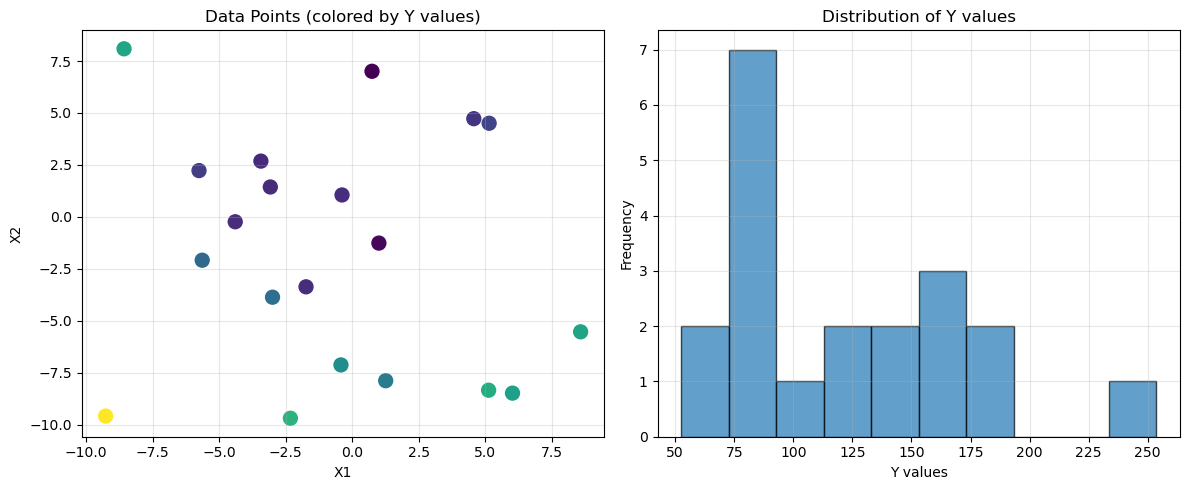

In [3]:
# Generate first dataset
print("Generating first dataset...")
X_data_1, Y_data_1 = gen_data(n=20, x_range=10)

print(f"Data generated:")
print(f"  X shape: {X_data_1.shape}")
print(f"  Y shape: {Y_data_1.shape}")
print(f"  Y range: [{Y_data_1.min():.2f}, {Y_data_1.max():.2f}]")
print(f"  Y mean: {Y_data_1.mean():.2f} ± {Y_data_1.std():.2f}")

# Visualize the data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot data points
ax1.scatter(X_data_1[:, 0], X_data_1[:, 1], c=Y_data_1, cmap="viridis", s=100)
ax1.set_xlabel("X1")
ax1.set_ylabel("X2")
ax1.set_title("Data Points (colored by Y values)")
ax1.grid(True, alpha=0.3)

# Plot Y values
ax2.hist(Y_data_1, bins=10, alpha=0.7, edgecolor="black")
ax2.set_xlabel("Y values")
ax2.set_ylabel("Frequency")
ax2.set_title("Distribution of Y values")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
# Build and sample from the first model
print("Building first model with uninformative priors...")
model_1 = build_model(X_data_1, Y_data_1, prior=None)

print("Model structure:")
print(model_1)

print("\nStarting MCMC sampling (this may take a few minutes)...")
with model_1:
    idata_1 = pm.sample(
        2000,
        tune=400,
        return_inferencedata=True,
        target_accept=0.95,
        max_treedepth=12,
        random_seed=42,
        nuts_sampler="numpyro",
    )

print("First sampling completed!")

Building first model with uninformative priors...
Model structure:

Starting MCMC sampling (this may take a few minutes)...


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setti

  0%|          | 0/2400 [00:00<?, ?it/s]

  0%|          | 0/2400 [00:00<?, ?it/s]

  0%|          | 0/2400 [00:00<?, ?it/s]

  0%|          | 0/2400 [00:00<?, ?it/s]

There were 4 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


First sampling completed!


### 4.2 Analyze First Run Results

In [5]:
# Print parameter summary
print("\n=== FIRST RUN PARAMETER SUMMARY ===")
summary_1 = az.summary(
    idata_1, var_names=["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2", "sigma"]
)
print(summary_1)


=== FIRST RUN PARAMETER SUMMARY ===
          mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
A0      51.147  3.756  44.364   58.547      0.076    0.049    2456.0   
A1      11.945  2.565   6.861   16.562      0.069    0.042    1448.0   
A2       7.430  2.700   2.066   12.114      0.079    0.057    1241.0   
omega1   2.456  0.131   2.192    2.667      0.004    0.005    1862.0   
omega2   2.111  0.473   1.512    2.904      0.047    0.065     200.0   
chi1     0.781  0.156   0.500    1.078      0.003    0.003    3178.0   
chi2     1.832  0.284   1.297    2.376      0.006    0.005    2520.0   
sigma   12.181  2.572   7.868   17.170      0.085    0.055     577.0   

        ess_tail  r_hat  
A0        3519.0   1.00  
A1        1243.0   1.00  
A2         928.0   1.00  
omega1     960.0   1.00  
omega2      87.0   1.03  
chi1      3519.0   1.00  
chi2      2502.0   1.00  
sigma      395.0   1.01  


### 4.3 Second Bayesian Inference Run (Using Posterior as Prior)

In [6]:
# Generate second dataset
print("Generating second dataset...")
X_data_2, Y_data_2 = gen_data(n=10, x_range=10)

print(f"Second dataset generated:")
print(f"  X shape: {X_data_2.shape}")
print(f"  Y range: [{Y_data_2.min():.2f}, {Y_data_2.max():.2f}]")
print(f"  Y mean: {Y_data_2.mean():.2f} ± {Y_data_2.std():.2f}")

# Build model using posterior from first run as prior
print("\nBuilding second model using first run's posterior as prior...")
model_2 = build_model(X_data_2, Y_data_2, prior=idata_1)

print("\nStarting second MCMC sampling...")
with model_2:
    idata_2 = pm.sample(
        2000,
        tune=400,
        return_inferencedata=True,
        target_accept=0.95,
        max_treedepth=12,
        random_seed=43,
        # nuts_sampler="numpyro",
    )

print("Second sampling completed!")

Generating second dataset...
Second dataset generated:
  X shape: (10, 2)
  Y range: [58.33, 163.70]
  Y mean: 96.07 ± 28.89

Building second model using first run's posterior as prior...

Starting second MCMC sampling...


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A0, A1, A2, omega1, omega2, chi1, chi2, sigma]


Output()

Sampling 4 chains for 400 tune and 2_000 draw iterations (1_600 + 8_000 draws total) took 114 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Second sampling completed!


### 4.4 Analyze Second Run Results

In [7]:
# Print parameter summary
print("\n=== SECOND RUN PARAMETER SUMMARY ===")
summary_2 = az.summary(
    idata_2, var_names=["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2", "sigma"]
)
print(summary_2)


=== SECOND RUN PARAMETER SUMMARY ===
          mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
A0      51.620  2.904  46.263   57.187      0.044    0.034    4432.0   
A1      10.818  2.613   6.096   15.518      0.047    0.077    4170.0   
A2       6.597  3.852   1.215   12.496      0.286    0.358     242.0   
omega1   2.429  0.253   1.645    2.663      0.021    0.029     425.0   
omega2   2.855  3.019  -4.103    8.205      0.674    0.521      31.0   
chi1     0.840  0.140   0.597    1.110      0.002    0.004    4563.0   
chi2     1.940  0.223   1.507    2.360      0.007    0.008     829.0   
sigma   11.415  2.141   7.809   15.613      0.082    0.035     647.0   

        ess_tail  r_hat  
A0        4640.0   1.00  
A1        3152.0   1.00  
A2         448.0   1.02  
omega1     213.0   1.02  
omega2      43.0   1.11  
chi1      3506.0   1.00  
chi2      1252.0   1.01  
sigma     2757.0   1.00  


## 6. Display Output and Visualizations

=== TRACE PLOTS FOR FIRST RUN ===


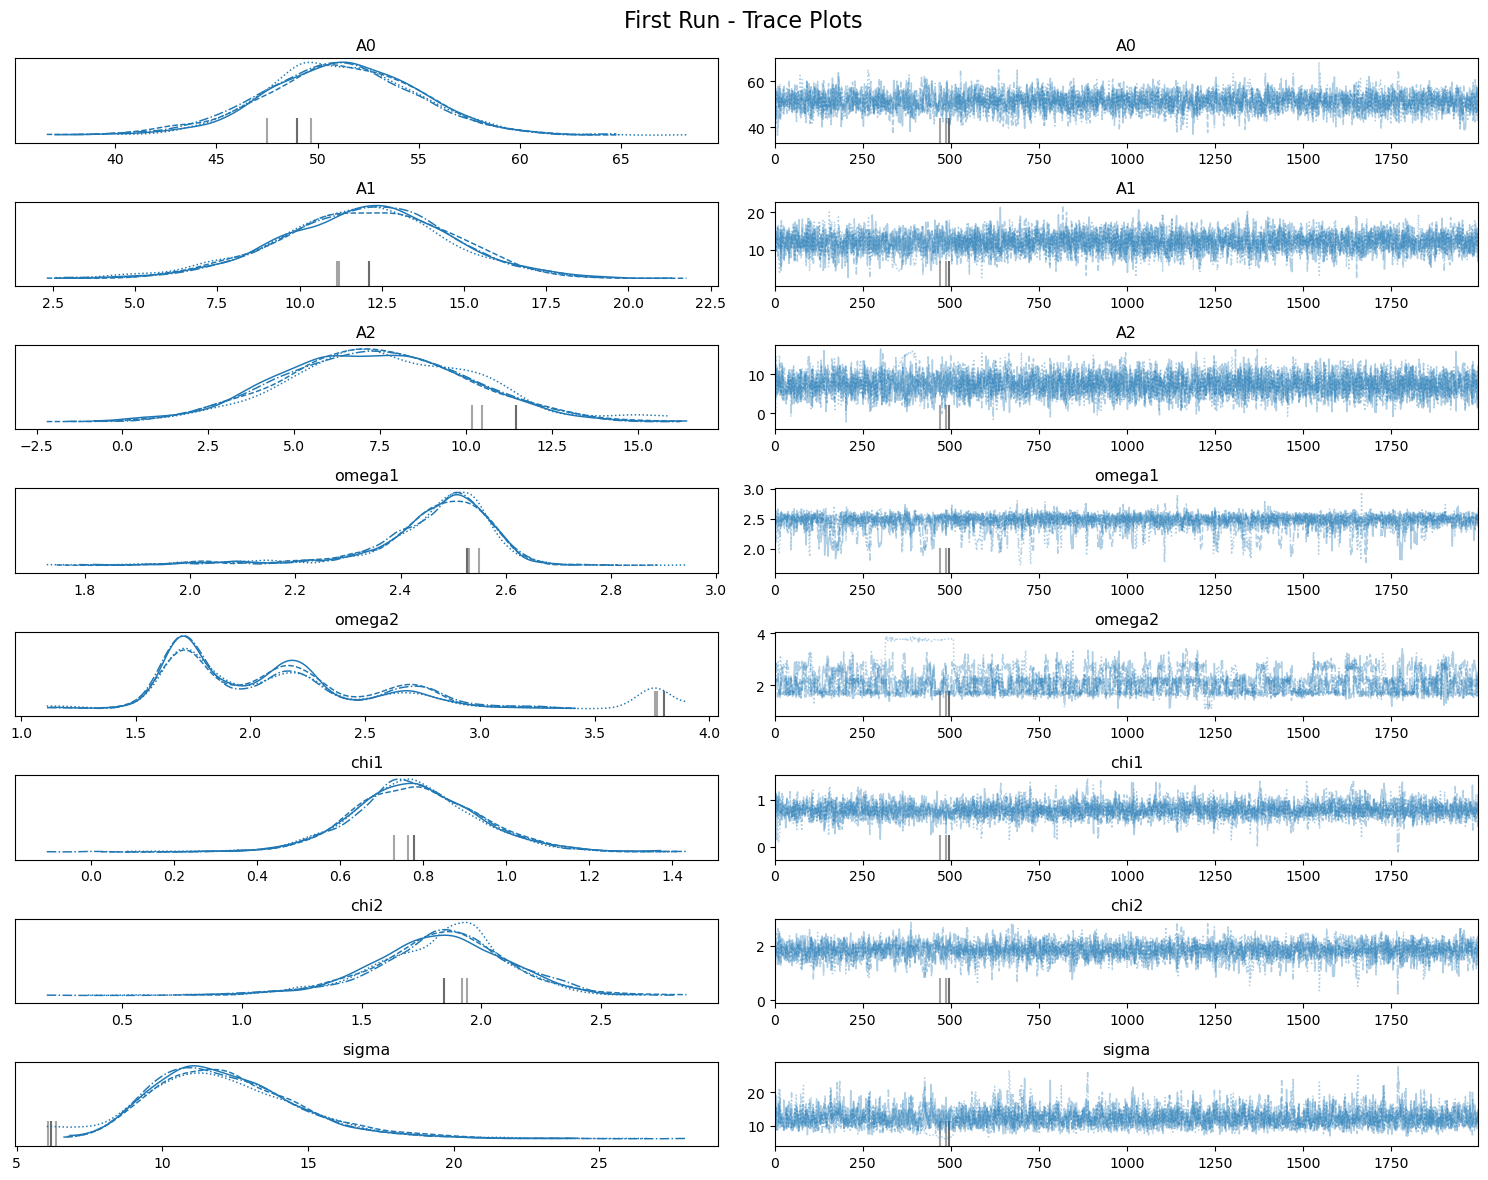

In [8]:
# Plot trace plots for first run
print("=== TRACE PLOTS FOR FIRST RUN ===")
az.plot_trace(
    idata_1,
    var_names=["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2", "sigma"],
    figsize=(15, 12),
)
plt.suptitle("First Run - Trace Plots", fontsize=16)
plt.tight_layout()
plt.show()

=== TRACE PLOTS FOR SECOND RUN ===


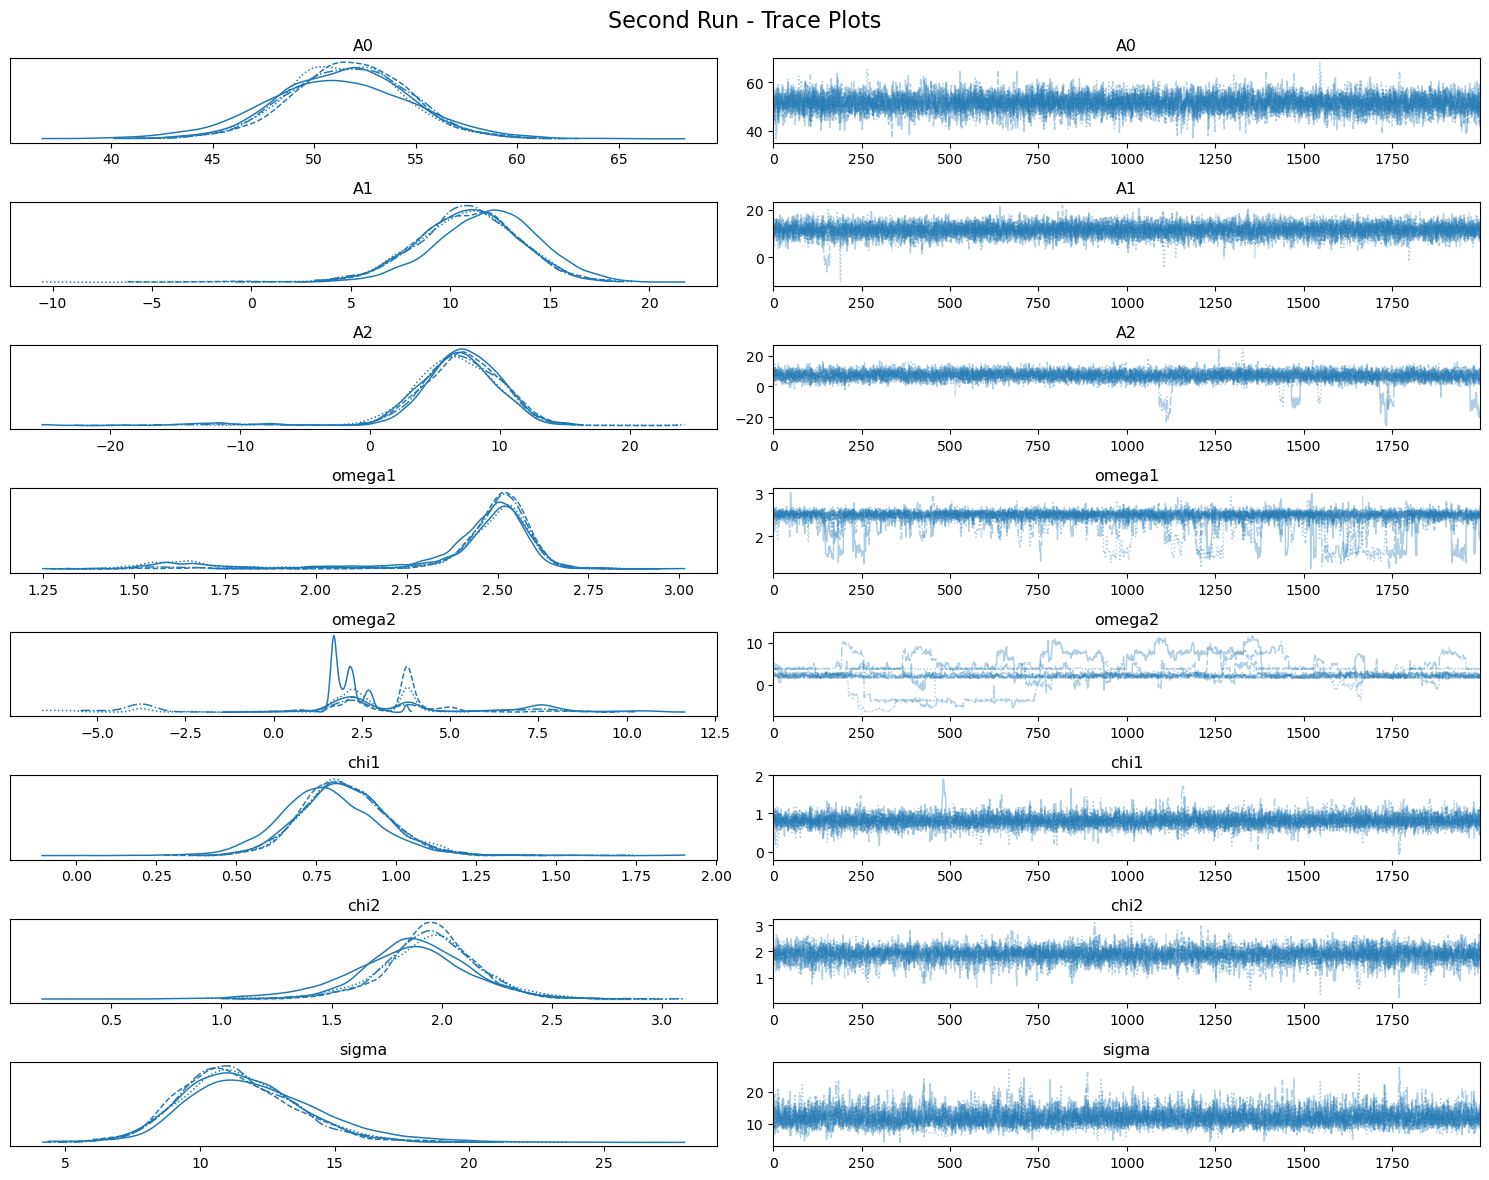

In [9]:
# Plot trace plots for second run
print("=== TRACE PLOTS FOR SECOND RUN ===")
ax = az.plot_trace(
    idata_1,
    var_names=["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2", "sigma"],
    figsize=(15, 12),
    divergences=False,
    combined=True,
    plot_kwargs={"color": "red"},
)

az.plot_trace(
    idata_2,
    var_names=["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2", "sigma"],
    figsize=(15, 12),
    divergences=False,
    # combined=True,
    axes=ax,
)
plt.suptitle("Second Run - Trace Plots", fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
def posterior_prediction(
    idata: az.InferenceData,
    X: np.ndarray,
    var_names: t.List[str] = ["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2"],
) -> np.ndarray:
    """Generate posterior predictive samples for given input data X.

    Args:
        idata (az.InferenceData): InferenceData object containing posterior samples.
        X (np.ndarray): Input data for prediction.
        var_names (t.List[str], optional): List of variable names to extract from posterior. Defaults to ["A0", "A1", "A2", "omega1", "omega2", "chi1", "chi2"].

    Returns:
        np.ndarray: Posterior predictive samples.
    """
    # Extract posterior samples for specified variables
    posterior_samples = list(
        [idata.posterior[var].values.reshape(-1, 1) for var in var_names]
    )

    # Generate predictions using the Rastrigin function
    Y_pred = pt_rastrigin(X, posterior_samples).eval()

    return Y_pred

In [11]:
xs = np.linspace(-10, 10, 100)
ys = np.linspace(-10, 10, 100)
X1_grid, X2_grid = np.meshgrid(xs, ys)
X_grid = np.vstack([X1_grid.ravel(), X2_grid.ravel()]).T
Y = posterior_prediction(
    idata_1,
    X_grid,
).reshape(-1, 100, 100)
print(f"Posterior prediction shape: {Y.shape}")

CI90 = np.percentile(Y, 95, axis=0) - np.percentile(Y, 5, axis=0)
# plot posterior predictions

Posterior prediction shape: (8000, 100, 100)


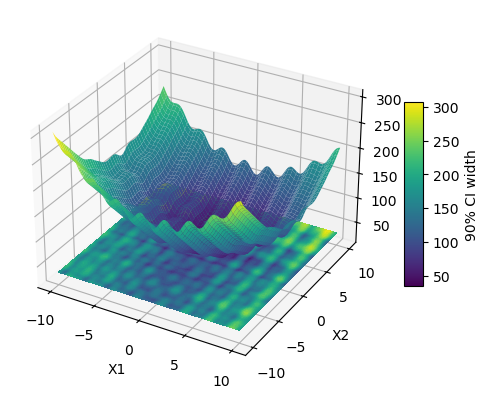

In [17]:
ax = plt.figure().add_subplot(projection="3d")
norm = plt.Normalize(Y.mean(axis=0).min(), Y.mean(axis=0).max())
ax.plot_surface(
    X1_grid,
    X2_grid,
    Y.mean(axis=0),
    cmap="viridis",
    # alpha=0.7,
    # facecolors=plt.cm.viridis(norm(CI90)),
)
# ax.plot_surface(
#     X1_grid,
#     X2_grid,
#     np.percentile(Y, 5, axis=0),
#     # cmap="viridis",
#     alpha=0.7,
# )
# add a colorbar
m = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
m.set_array([])
plt.colorbar(m, ax=ax, shrink=0.5, aspect=10, label="90% CI width")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.contourf(
    X1_grid,
    X2_grid,
    CI90,
    zdir="z",
    offset=Y.mean(axis=0).min(),
    cmap="viridis",
    # alpha=0.5,
    levels=50,
)
plt.show()